# Feature Visualization — a hands-on reimplementation

This notebook reimplements, from scratch in PyTorch, the ideas of

> Chris Olah, Alexander Mordvintsev, Ludwig Schubert. **"Feature Visualization: How neural networks build up their understanding of images."** *Distill*, 2017. https://distill.pub/2017/feature-visualization/

The article asks a simple question: *what is a neuron in a vision network looking for?*  Its answer is to
**optimize an input image** so that it excites the neuron, and it spends most of its length on the details that make
that actually work: choosing an objective, getting diverse results, and taming the high-frequency "adversarial"
noise that naive optimization produces.

We follow the article section by section:

| # | Article section | What we build |
|---|---|---|
| 1–3 | — | Model, activation hooks, objectives, image parameterizations, transformations, the render loop |
| 4 | *Feature Visualization by Optimization* / *Optimization Objectives* | neurons, channels, layers (DeepDream), class logits & probabilities, negative directions |
| 5 | *Why visualize by optimization?* | dataset examples (top activating images) vs. optimized images |
| 6 | *Diversity* | a Gram-matrix diversity term over a batch |
| 7 | *Interaction between Neurons* | neuron arithmetic, random directions, interpolation |
| 8 | *The Enemy of Feature Visualization* | naive optimization, frequency penalization, transformation robustness |
| 9 | *Preconditioning and Parameterization* | decorrelated Fourier-space parameterization |
| 10 | — | **export**: render every channel of the network into an atlas for the 3D viewer |

**Model.** We use the same network as the article: Google's original **InceptionV1** (GoogLeNet) trained on
ImageNet, as used by [Lucid](https://github.com/tensorflow/lucid), loaded in PyTorch through its port
[Lucent](https://github.com/greentfrapp/lucent). Layer names (`mixed4a`, …) and channel numbers match the
article and the Lucid tutorials — e.g. `mixed4a:476`.

> Why not `torchvision.models.googlenet`? It has the same architecture but was re-trained (with BatchNorm, and
> 3×3 convs instead of 5×5), and its feature visualizations come out covered in a checkerboard pattern no matter
> how we optimize. See `transform_lab.ipynb` for the comparison.

**Runtime.** Go to *Runtime → Change runtime type → GPU* (a T4 is plenty). Each 2048-step render takes ~20–30
seconds on a GPU; on CPU it works, but slowly — lower `STEPS` / `SIZE` below.

## 1. Setup

In [1]:
%pip install -q --no-deps torch-lucent   # provides the original InceptionV1 weights

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torchvision.transforms.functional import gaussian_blur

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)
if device.type == "cpu":
    print("⚠️  No GPU found: Runtime → Change runtime type → GPU is strongly recommended.")

# Global defaults for every render in the notebook. Lower these if you are on CPU.
STEPS = 2048  # optimization steps per visualization
SIZE = 224    # image side in pixels


def seed_everything(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


seed_everything(0)

torch 2.12.0+cu130 | device: cuda


## 2. The model and its activations

We load InceptionV1 and freeze it: during feature visualization the **network is fixed and the image is the
parameter**. The model expects pixel values in `[-117, 138]` (the original Caffe/TensorFlow preprocessing), so
`run_model` maps our `[0, 1]` images with `x * 255 - 117`.

To read intermediate activations we register forward hooks. For every layer we record:

* `mixed4a` — the block output (concatenation of its four branches, **after** ReLU);
* `mixed4a_pre_relu` — the same channels **before** the ReLU (the outputs of the four branches' last convs).

Pre-ReLU activations matter because a post-ReLU unit that is "off" has zero gradient, and because they let us
*minimize* a neuron — the article's "negative" visualizations — and use linear directions in activation space.

> Lucent's port uses a "redirected" ReLU by default: in the backward pass it lets a little gradient (×0.1) through
> units that are off, so the optimization never gets stuck at the start. This is a trick from Lucid.

In [2]:
import urllib.request
from lucent.modelzoo import inceptionv1

model = inceptionv1(pretrained=True).eval().to(device)
for p in model.parameters():
    p.requires_grad_(False)

# Class names in this model's output order (index 0 is a placeholder; outputs 1001–1007 are unused).
LABELS_URL = "https://storage.googleapis.com/modelzoo/labels/ImageNet_alternate.txt"
CLASSES = urllib.request.urlopen(LABELS_URL).read().decode().strip().split("\n")
assert len(CLASSES) == 1001 and CLASSES[0] == "dummy"

CONV_LAYERS = ["conv2d0", "conv2d1", "conv2d2"]
INCEPTION_LAYERS = ["mixed3a", "mixed3b", "mixed4a", "mixed4b", "mixed4c",
                    "mixed4d", "mixed4e", "mixed5a", "mixed5b"]
BRANCHES = ["1x1", "3x3", "5x5", "pool_reduce"]   # the last conv of each Inception branch

_acts = {}  # filled by the hooks on every forward pass
_pre = {}   # pre-ReLU pieces, one per Inception branch


def _save_output(name):
    def hook(module, inputs, output):
        _acts[name] = output
    return hook


def _save_pre_relu(name, branch):
    def hook(module, inputs, output):
        _pre.setdefault(name, {})[branch] = output
    return hook


for name in CONV_LAYERS + INCEPTION_LAYERS:
    getattr(model, name).register_forward_hook(_save_output(name))
for name in CONV_LAYERS:
    getattr(model, f"{name}_pre_relu_conv").register_forward_hook(_save_pre_relu(name, 0))
for name in INCEPTION_LAYERS:
    for i, branch in enumerate(BRANCHES):
        getattr(model, f"{name}_{branch}_pre_relu_conv").register_forward_hook(_save_pre_relu(name, i))


class _StopForward(Exception):
    pass


def _stop(module, inputs, output):
    raise _StopForward


# The port's classifier uses a fixed 7×7 average pool, which fails when random scaling makes the image smaller
# than 224 px. So we stop the forward pass after mixed5b and apply the classifier ourselves with a global average
# pool (identical at 224 px, and works at any size).
model.mixed5b.register_forward_hook(_stop)


def run_model(img):
    # img: (N, 3, H, W) in [0, 1]. Returns a dict {layer name -> activation tensor}.
    _acts.clear()
    _pre.clear()
    try:
        model(img * 255 - 117)
    except _StopForward:
        pass
    acts = dict(_acts)
    for name, branches in _pre.items():
        acts[name + "_pre_relu"] = torch.cat([branches[i] for i in sorted(branches)], dim=1)
    pooled = acts["mixed5b"].mean(dim=(2, 3))
    acts["logits"] = model.softmax2_pre_activation_matmul(pooled)[:, :len(CLASSES)]
    return acts


with torch.no_grad():
    probe = run_model(torch.rand(1, 3, SIZE, SIZE, device=device))
print(f"{'layer':<14}{'channels':>9}{'spatial':>10}")
for name in CONV_LAYERS + INCEPTION_LAYERS:
    a = probe[name]
    print(f"{name:<14}{a.shape[1]:>9}{a.shape[2]:>6}x{a.shape[3]}")

layer          channels   spatial
conv2d0              64   112x112
conv2d1              64    56x56
conv2d2             192    56x56
mixed3a             256    28x28
mixed3b             480    28x28
mixed4a             508    14x14
mixed4b             512    14x14
mixed4c             512    14x14
mixed4d             528    14x14
mixed4e             832    14x14
mixed5a             832     7x7
mixed5b            1024     7x7


## 3. The toolkit

Feature visualization has four moving parts, which we build one at a time:

1. **Objective** — a scalar function of the activations that we want to *maximize*.
2. **Parameterization** — how the image is produced from the tensors we actually optimize.
3. **Transformations** — random jitter / scale / rotation applied before each forward pass.
4. **The optimization loop** — Adam on the parameters, maximizing the objective.

(2) and (3) are the "secret sauce" that the second half of the article (Sections 8–9 here) is about. We define
them now so that the early sections can use good defaults, and take them apart later.

### 3.1 Objectives

An `Objective` wraps a function `acts -> scalar`. Objectives can be added, subtracted and scaled, which is all we
need for the article's neuron arithmetic, interpolations and regularizers. The optional `batch=i` argument
applies an objective to a single image of the batch.

Following the article's terminology (Figure *"Different optimization objectives"*):

* **neuron** — one unit at one spatial position: `layer[n, x, y]`
* **channel** — a feature map averaged over all positions: `layer[n, :, :]`
* **layer / DeepDream** — the squared norm of a whole layer: `layer[:, :, :]²`
* **class logit** / **class probability** — `pre_softmax[k]` / `softmax[k]`
* **direction** — the dot product with an arbitrary vector in a layer's activation space.

In [3]:
class Objective:
    # A differentiable scalar function of the activations, to be maximized.

    def __init__(self, fn, name=""):
        self.fn = fn
        self.name = name

    def __call__(self, acts):
        return self.fn(acts)

    def __add__(self, other):
        if isinstance(other, (int, float)):
            return Objective(lambda a: self(a) + other, self.name)
        return Objective(lambda a: self(a) + other(a), f"{self.name} + {other.name}")

    def __radd__(self, other):  # makes sum([...]) work
        return self + other

    def __mul__(self, k):
        return Objective(lambda a: k * self(a), f"{k:g}·{self.name}")

    __rmul__ = __mul__

    def __neg__(self):
        return Objective(lambda a: -self(a), f"−{self.name}")

    def __sub__(self, other):
        return self + (-other)

    def __repr__(self):
        return f"Objective({self.name})"


def _pick(t, batch):
    return t if batch is None else t[batch:batch + 1]


def neuron(layer, n, x=None, y=None, batch=None):
    # A single unit; defaults to the spatial center of the feature map.
    def fn(a):
        t = _pick(a[layer], batch)
        h, w = t.shape[-2:]
        # clamp: random scaling can make the feature map slightly smaller than at the nominal size
        yy = h // 2 if y is None else min(y, h - 1)
        xx = w // 2 if x is None else min(x, w - 1)
        return t[:, n, yy, xx].mean()
    return Objective(fn, f"neuron {layer}:{n}")


def channel(layer, n, batch=None):
    return Objective(lambda a: _pick(a[layer], batch)[:, n].mean(), f"{layer}:{n}")


def deepdream(layer, batch=None):
    return Objective(lambda a: (_pick(a[layer], batch) ** 2).mean(), f"deepdream {layer}")


def class_logit(k, batch=None):
    return Objective(lambda a: _pick(a["logits"], batch)[:, k].mean(), f"logit '{CLASSES[k]}'")


def class_prob(k, batch=None):
    return Objective(lambda a: _pick(a["logits"], batch).softmax(-1)[:, k].mean(), f"p('{CLASSES[k]}')")


def direction(layer, vec, batch=None):
    # Dot product between the activations at every position and the direction `vec`, averaged.
    def fn(a):
        t = _pick(a[layer], batch)
        v = torch.as_tensor(vec, dtype=t.dtype, device=t.device).view(1, -1, 1, 1)
        return (t * v).sum(1).mean()
    return Objective(fn, f"direction in {layer}")


def diversity(layer):
    # Higher when the images of a batch have dissimilar *styles* (Section 6).
    def fn(a):
        t = a[layer]
        n, c = t.shape[:2]
        flat = t.reshape(n, c, -1)
        grams = F.normalize((flat @ flat.transpose(1, 2)).reshape(n, -1), dim=1)
        sims = grams @ grams.T
        return -(sims.sum() - sims.diagonal().sum()) / n
    return Objective(fn, f"diversity {layer}")


def total_variation():
    # Mean absolute difference between neighbouring pixels of the (untransformed) image. A *penalty*: subtract it.
    def fn(a):
        img = a["image"]
        return ((img[..., 1:, :] - img[..., :-1, :]).abs().mean()
                + (img[..., :, 1:] - img[..., :, :-1]).abs().mean())
    return Objective(fn, "TV")

### 3.2 Image parameterizations

We never optimize pixels in $[0,1]$ directly. Instead an image is a function of some unconstrained tensors,
`params -> image`, and the final `sigmoid` keeps it a valid image.

* **Pixel** parameterization: one free value per pixel and channel. The obvious choice — and, as Section 8 shows,
  a bad one.
* **Fourier** parameterization: the parameters are the image's 2D Fourier coefficients, each scaled by
  $1/\text{frequency}$ so that, at initialization and under gradient descent, all frequencies have roughly equal
  energy (natural images have a $1/f$ spectrum).
* **Decorrelated color**: the three channels we optimize are not RGB but (roughly) the principal components of
  ImageNet colors; a fixed $3\times3$ matrix maps them back to RGB.

Section 9 explains why the last two help so much. The matrix below is the "square root" of ImageNet's color
covariance used by Lucid.

In [4]:
COLOR_CORRELATION_SVD_SQRT = torch.tensor([[0.26, 0.09, 0.02],
                                           [0.27, 0.00, -0.05],
                                           [0.27, -0.09, 0.03]], device=device)
COLOR_CORRELATION_NORMALIZED = COLOR_CORRELATION_SVD_SQRT / COLOR_CORRELATION_SVD_SQRT.norm(dim=0).max()


def to_valid_rgb(t, decorrelate=True):
    # Unconstrained (N, 3, H, W) tensor -> image in [0, 1].
    if decorrelate:
        t = torch.einsum("nchw,dc->ndhw", t, COLOR_CORRELATION_NORMALIZED)
    return torch.sigmoid(t)


def pixel_image(shape, sd=0.01):
    t = (torch.randn(*shape, device=device) * sd).requires_grad_(True)
    return [t], lambda: t


def fft_image(shape, sd=0.01, decay_power=1.0):
    n, c, h, w = shape
    fy = np.fft.fftfreq(h)[:, None]
    fx = np.fft.rfftfreq(w)[None, :]
    freqs = np.sqrt(fx ** 2 + fy ** 2)
    scale = 1.0 / np.maximum(freqs, 1.0 / max(h, w)) ** decay_power
    scale = torch.tensor(scale, dtype=torch.float32, device=device)[None, None]
    spectrum = (torch.randn(n, c, h, w // 2 + 1, 2, device=device) * sd).requires_grad_(True)

    def image():
        coeffs = torch.view_as_complex(spectrum) * scale
        return torch.fft.irfft2(coeffs, s=(h, w), norm="ortho") / 4.0

    return [spectrum], image


def image_param(shape, fft=True, decorrelate=True, sd=0.01):
    # Returns (list of tensors to optimize, function producing the current image in [0, 1]).
    params, raw = (fft_image if fft else pixel_image)(shape, sd=sd)
    return params, lambda: to_valid_rgb(raw(), decorrelate)

### 3.3 Transformation robustness

Before every forward pass we randomly pad, jitter, scale and rotate the image. Patterns that only excite the neuron
at one exact pixel alignment (the adversarial noise of Section 8) don't survive this, so the optimizer is pushed
toward robust, recognisable structure. These are the same transforms Lucid uses by default.

In [5]:
def pad(p, value=0.5):
    return lambda x: F.pad(x, [p] * 4, mode="constant", value=value)


def jitter(d):
    # Random crop that removes d pixels in each dimension.
    def f(x):
        h, w = x.shape[-2:]
        ox, oy = np.random.randint(0, d + 1, size=2)
        return x[..., oy:oy + h - d, ox:ox + w - d]
    return f


def random_scale(scales):
    return lambda x: F.interpolate(x, scale_factor=random.choice(scales), mode="bilinear", align_corners=False)


def random_rotate(angles):
    def f(x):
        a = math.radians(random.choice(angles))
        theta = torch.tensor([[math.cos(a), -math.sin(a), 0.0],
                              [math.sin(a), math.cos(a), 0.0]], device=x.device, dtype=x.dtype)
        grid = F.affine_grid(theta.expand(x.shape[0], 2, 3), list(x.shape), align_corners=False)
        return F.grid_sample(x, grid, padding_mode="border", align_corners=False)
    return f


def compose(transforms):
    def f(x):
        for t in transforms:
            x = t(x)
        return x
    return f


STANDARD_TRANSFORMS = [
    pad(12),
    jitter(8),
    random_scale([1 + (i - 5) / 50 for i in range(11)]),
    random_rotate(list(range(-10, 11)) + 5 * [0]),
    jitter(4),
]

### 3.4 The render loop

`render` puts it together: build the image from its parameters, transform it, run the network, and take an Adam
step that *increases* the objective. Regularizers that look at the image itself (like total variation) read it
from `acts["image"]`.

Pass `thresholds=[...]` to get snapshots during optimization, and `blur_every=k` to blur pixel parameters every
`k` steps (one of the frequency-penalization tricks in Section 8).

In [6]:
def render(objective, param_f=None, transforms=None, steps=None, lr=0.05, size=None, batch=1,
           thresholds=None, blur_every=0, seed=0):
    # Optimizes an image to maximize `objective`.
    # Returns an (N, 3, H, W) CPU tensor, or {step: images} if `thresholds` is given.
    seed_everything(seed)
    steps = steps or STEPS
    size = size or SIZE
    if param_f is None:
        param_f = lambda: image_param((batch, 3, size, size))
    if transforms is None:
        transforms = STANDARD_TRANSFORMS
    transform = compose(transforms)

    params, image_f = param_f()
    optimizer = torch.optim.Adam(params, lr=lr)
    snapshots = {}
    for step in range(1, steps + 1):
        optimizer.zero_grad()
        img = image_f()
        acts = run_model(transform(img))
        acts["image"] = img
        loss = -objective(acts)
        loss.backward()
        optimizer.step()
        if blur_every and step % blur_every == 0:
            with torch.no_grad():
                for p in params:
                    p.copy_(gaussian_blur(p, kernel_size=5, sigma=1.0))
        if thresholds and step in thresholds:
            snapshots[step] = image_f().detach().cpu()
    return snapshots if thresholds else image_f().detach().cpu()


@torch.no_grad()
def measure_objective(objective, img):
    # Value of `objective` on an already rendered image (no transformations).
    img = img.to(device)
    acts = run_model(img)
    acts["image"] = img
    return objective(acts).item()


def show(images, titles=None, ncols=None, scale=3.0, suptitle=None):
    # images: an (N, 3, H, W) tensor or a list of (3, H, W) / (N, 3, H, W) tensors.
    if isinstance(images, torch.Tensor):
        images = [images]
    flat = [im for t in images for im in (t if t.dim() == 4 else [t])]
    ncols = ncols or len(flat)
    nrows = math.ceil(len(flat) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(scale * ncols, scale * nrows + (0.4 if suptitle else 0)),
                             squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for i, (ax, im) in enumerate(zip(axes.flat, flat)):
        ax.imshow(im.permute(1, 2, 0).clamp(0, 1).cpu().numpy())
        if titles is not None and i < len(titles):
            ax.set_title(titles[i], fontsize=9)
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

A first visualization — a channel in the middle of the network:

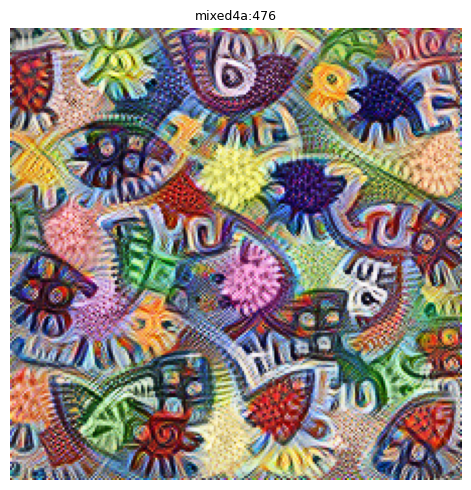

In [8]:
img = render(channel("mixed4a", 476))
show(img, ["mixed4a:476"], scale=5)

## 4. Optimization objectives

> *"Neural networks are, generally speaking, differentiable with respect to their inputs. If we want to find out
> what kind of input would cause a certain behavior — whether that's an internal neuron firing or the final output
> behavior — we can use derivatives to iteratively tweak the input towards that goal."*

The article's first figure compares *what* we optimize. The choice matters:

* a **neuron** (one spatial position) produces a feature roughly in the middle, at the scale of its receptive field;
* a **channel** asks for the feature *everywhere*, giving a texture;
* a **layer** (DeepDream) amplifies whatever the layer already sees, mixing many features;
* **class logits** produce scenes with recognisable parts of the class;
* **class probabilities** are a worse objective: the easiest way to raise a softmax probability is often to
  *suppress the other classes* rather than make the target more present.

Change `LAYER` / `N` and rerun — middle layers (`mixed4a`–`4c`) tend to give the most interpretable results.

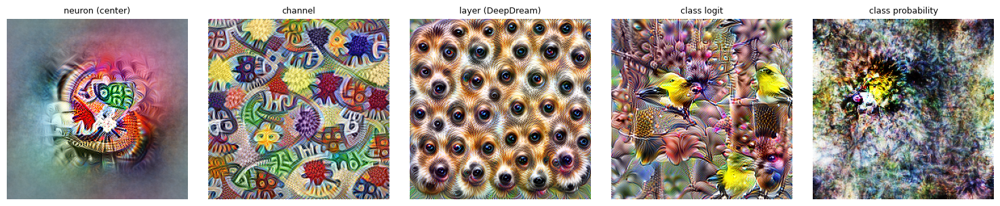

In [9]:
LAYER, N = "mixed4a", 476

objectives = [
    neuron(LAYER + "_pre_relu", N),
    channel(LAYER, N),
    deepdream(LAYER),
    class_logit(CLASSES.index("goldfinch")),
    class_prob(CLASSES.index("goldfinch")),
]
show([render(obj) for obj in objectives],
     ["neuron (center)", "channel", "layer (DeepDream)", "class logit", "class probability"])

### Going deeper

Optimizing channels at successive layers reproduces the article's overview figure: edges → textures → patterns →
parts → objects. Channel indices are arbitrary picks; try others.

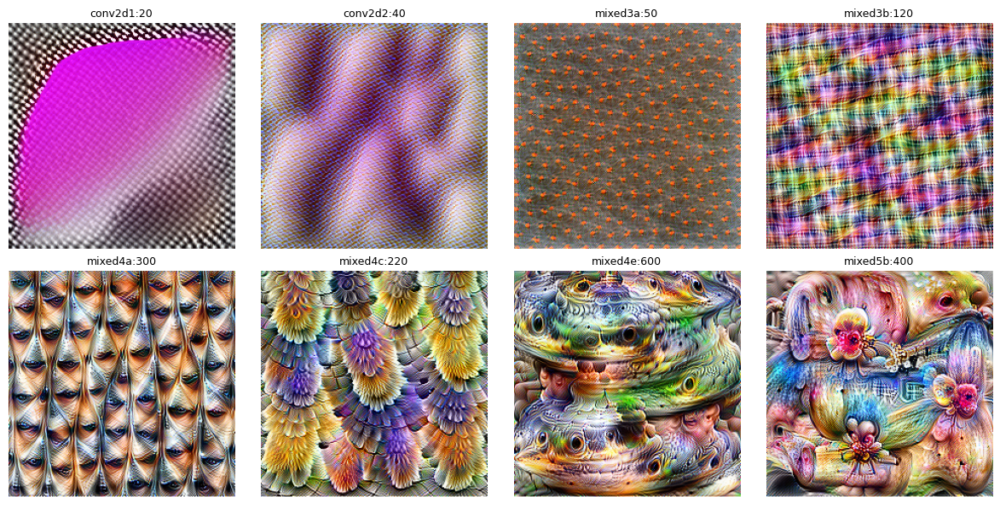

In [10]:
progression = [("conv2d1", 20), ("conv2d2", 40), ("mixed3a", 50), ("mixed3b", 120),
               ("mixed4a", 300), ("mixed4c", 220), ("mixed4e", 600), ("mixed5b", 400)]
show([render(channel(layer, n)) for layer, n in progression],
     [f"{layer}:{n}" for layer, n in progression], ncols=4)

### Negative directions

Using the pre-ReLU activations we can also *minimize* a channel. The article shows that the most negative
stimulus often has a meaningful relationship with the positive one (e.g. contrasting colors or orientations).

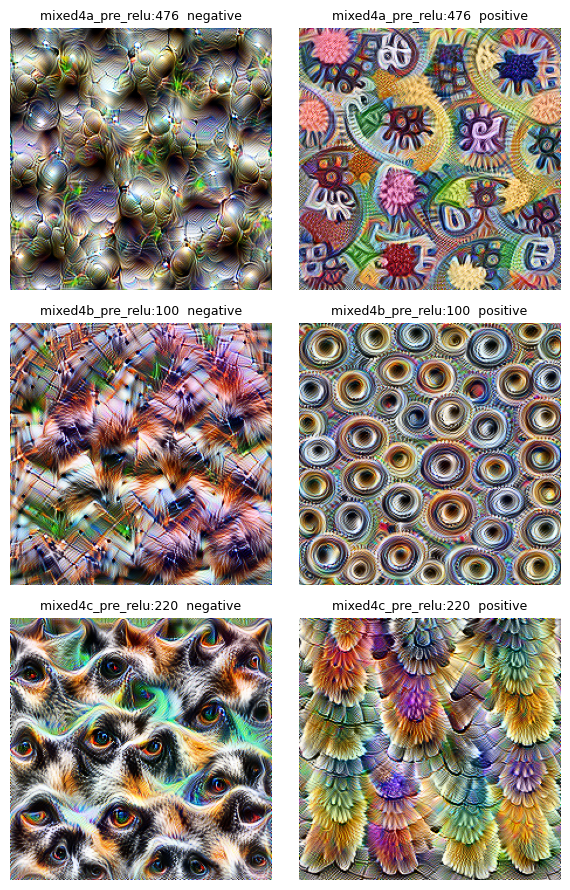

In [11]:
pairs = [("mixed4a_pre_relu", 476), ("mixed4b_pre_relu", 100), ("mixed4c_pre_relu", 220)]
images, titles = [], []
for layer, n in pairs:
    images += [render(-channel(layer, n)), render(channel(layer, n))]
    titles += [f"{layer}:{n}  negative", f"{layer}:{n}  positive"]
show(images, titles, ncols=2)

### Neurons at different positions

A neuron objective is pinned to one spatial position of the feature map — move it and the feature moves with it.

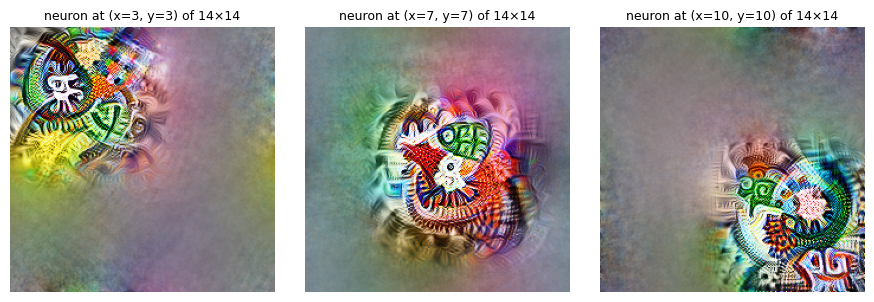

In [12]:
layer, n = "mixed4a_pre_relu", 476
h, w = probe[layer].shape[-2:]
positions = [(w // 4, h // 4), (w // 2, h // 2), (3 * w // 4, 3 * h // 4)]
show([render(neuron(layer, n, x=x, y=y)) for x, y in positions],
     [f"neuron at (x={x}, y={y}) of {w}×{h}" for x, y in positions])

## 5. Why visualize by optimization? Dataset examples

The alternative to optimization is to search a dataset for the images that activate a neuron most. Dataset
examples are great because they show *real* inputs, but they can't separate cause from correlation: if every top
image of a "dog face" neuron also contains grass, is the neuron about the face, or the grass? Optimization isolates
what actually causes the activation. The article argues the two are complementary.

ImageNet itself isn't freely downloadable, so we use [Imagenette](https://github.com/fastai/imagenette): a
10-class subset of ImageNet (≈95 MB). With only 10 classes our "dataset examples" are much less varied than the
article's, but the comparison is still instructive.

In [13]:
import os
import urllib.request
import tarfile
from torchvision import datasets, transforms as T

URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"
if not os.path.exists("imagenette2-160"):
    urllib.request.urlretrieve(URL, "imagenette2-160.tgz")
    with tarfile.open("imagenette2-160.tgz") as tar:
        tar.extractall(filter="data")

dataset = datasets.ImageFolder("imagenette2-160/val", transform=T.Compose([T.Resize(160), T.CenterCrop(160),
                                                                         T.ToTensor()]))
loader = torch.utils.data.DataLoader(dataset, batch_size=128, num_workers=2)
print(len(dataset), "images")

# For a few layers, record the max (over positions) activation of every channel on every image.
EXAMPLE_LAYERS = ["mixed3b_pre_relu", "mixed4a_pre_relu", "mixed4c_pre_relu", "mixed4e_pre_relu"]
max_acts = {layer: [] for layer in EXAMPLE_LAYERS}
with torch.no_grad():
    for x, _ in loader:
        acts = run_model(x.to(device))
        for layer in EXAMPLE_LAYERS:
            max_acts[layer].append(acts[layer].amax(dim=(2, 3)).cpu())
max_acts = {layer: torch.cat(v) for layer, v in max_acts.items()}


def dataset_examples(layer, n, k=8, largest=True):
    idx = max_acts[layer][:, n].topk(k, largest=largest).indices
    return torch.stack([dataset[i][0] for i in idx])

3925 images


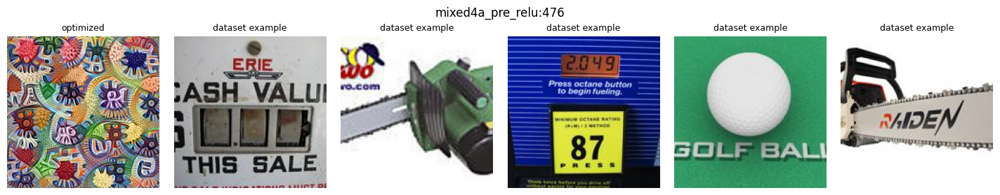

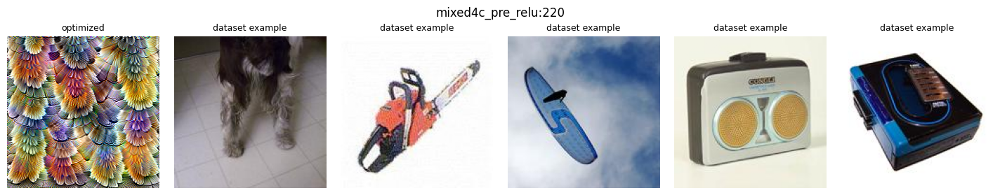

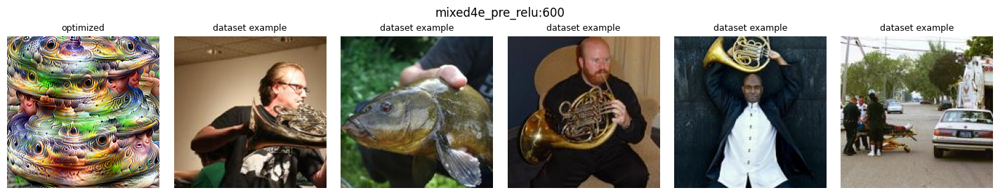

In [14]:
for layer, n in [("mixed4a_pre_relu", 476), ("mixed4c_pre_relu", 220), ("mixed4e_pre_relu", 600)]:
    show([render(channel(layer, n)), dataset_examples(layer, n, k=5)],
         ["optimized"] + ["dataset example"] * 5, scale=2.4, suptitle=f"{layer}:{n}")

We can also go the other way: pick the channels that respond most selectively to one Imagenette class, and look at
what they want to see.

channels of mixed4e_pre_relu most selective for class n01440764: [346, 436, 681, 715]


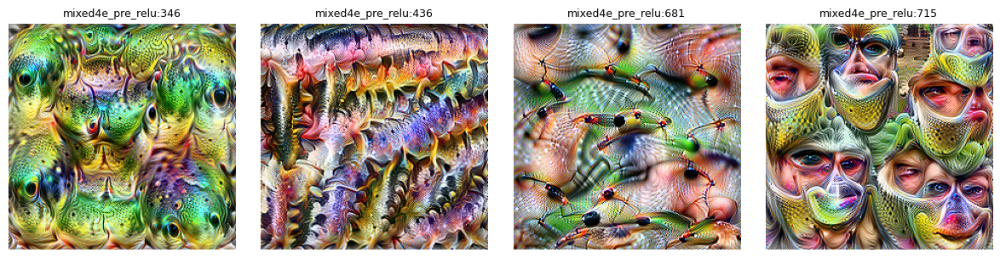

In [15]:
layer = "mixed4e_pre_relu"
targets = torch.tensor(dataset.targets)
cls = 0  # 0 = tench (a fish); see dataset.classes for the WordNet ids of the 10 classes
selectivity = max_acts[layer][targets == cls].mean(0) - max_acts[layer][targets != cls].mean(0)
top = selectivity.topk(4).indices.tolist()
print(f"channels of {layer} most selective for class {dataset.classes[cls]}:", top)
show([render(channel(layer, n)) for n in top], [f"{layer}:{n}" for n in top])

## 6. Diversity

A single visualization can mislead: a neuron may respond to several quite different things (dog faces seen from
the front *and* from the side, or to two unrelated concepts — "polysemantic" neurons). Dataset examples show this
variety naturally; optimization needs help.

The article's approach: optimize a **batch** of images and add a penalty for their **similarity**. Similarity is
measured as the cosine similarity between the images' *Gram matrices* in some layer — the "style" representation of
neural style transfer — so the images are pushed toward visually different styles of the same feature:

$$
C_\text{diversity} = -\sum_{i}\sum_{j\neq i} \frac{\operatorname{vec}(G_i)\cdot\operatorname{vec}(G_j)}{\|\operatorname{vec}(G_i)\|\,\|\operatorname{vec}(G_j)\|}
$$

Row 1: four images optimized independently from different random starts. Row 2: the same, plus the diversity term.

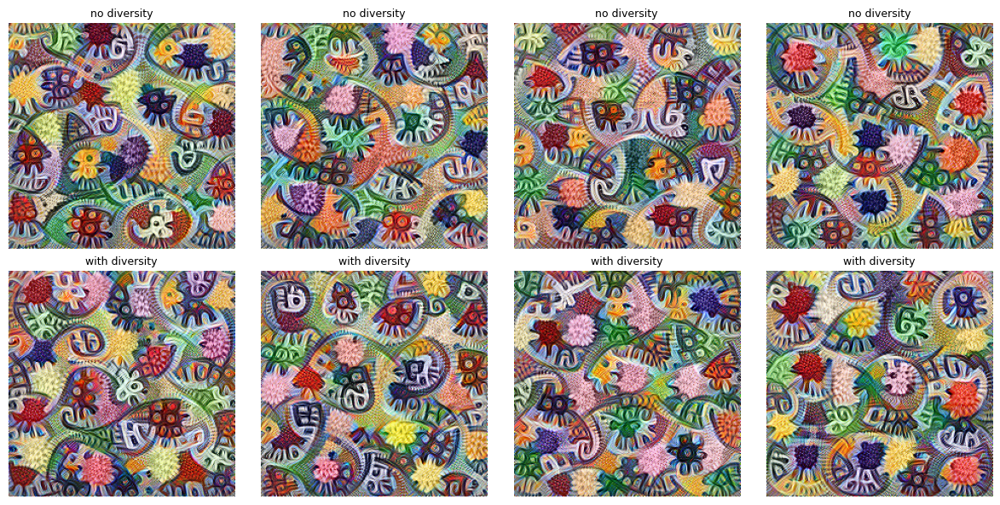

In [16]:
layer, n = "mixed4a", 476
plain = render(channel(layer, n), batch=4)
diverse = render(channel(layer, n) + 1e2 * diversity(layer), batch=4)
show([plain, diverse], ["no diversity"] * 4 + ["with diversity"] * 4, ncols=4)

The weight of the diversity term is a knob (1e2 is Lucid's value for this model): too
small and nothing changes, too big and the images stop
activating the neuron. Try a few values, and try putting the diversity term in an *earlier* layer than the
objective (more variety in low-level style) or a *later* one.

## 7. Interaction between neurons

Neurons are just one basis for a layer's activation space; the article asks what happens in other directions.

### Neuron arithmetic

Optimizing the sum of two channels often produces an image that *combines* both features — sometimes in a
surprising way.

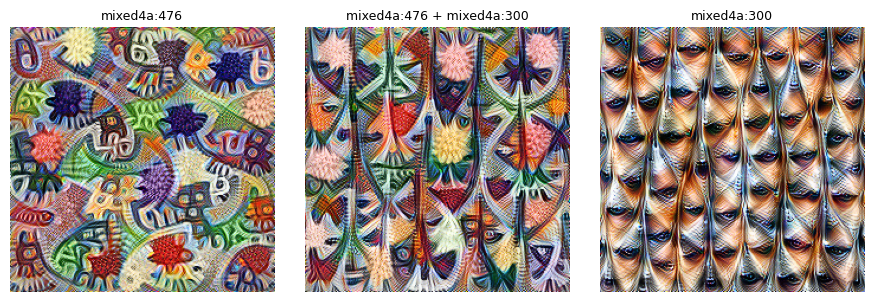

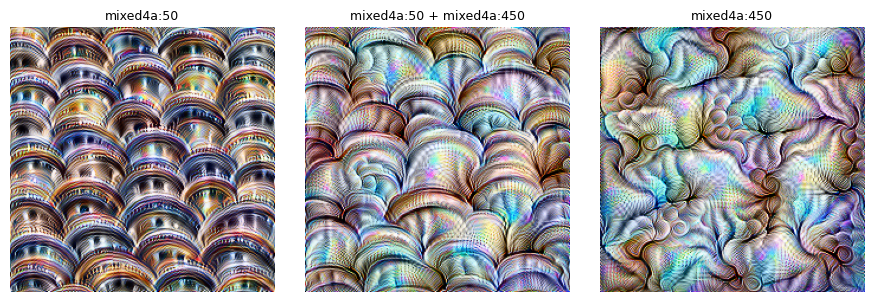

In [17]:
layer = "mixed4a"
for a_, b_ in [(476, 300), (50, 450)]:
    show([render(channel(layer, a_)), render(channel(layer, a_) + channel(layer, b_)), render(channel(layer, b_))],
         [f"{layer}:{a_}", f"{layer}:{a_} + {layer}:{b_}", f"{layer}:{b_}"])

### Random directions

Is there something special about the neuron basis? Visualizing random directions in activation space also gives
interpretable-looking features, though the article notes they tend to look *less* focused than neuron directions
— evidence that the basis isn't entirely arbitrary.

In [ ]:
layer = "mixed4a_pre_relu"
gen = torch.Generator().manual_seed(1)
directions = [torch.randn(probe[layer].shape[1], generator=gen) for _ in range(4)]
show([render(direction(layer, v)) for v in directions], [f"random direction {i}" for i in range(4)])

### Interpolation

To see how two features blend, optimize a batch of images where image $i$ maximizes
$(1-t_i)\,\text{A} + t_i\,\text{B}$ for $t_i$ going from 0 to 1.

If each image is independent, consecutive frames look unrelated. The article's trick is to give all images a
**shared** parameterization component in addition to their own, so they share structure and the interpolation
looks smooth.

In [ ]:
def interpolation_param(n, size, shared=True):
    own_params, own = fft_image((n, 3, size, size))
    if not shared:
        return own_params, lambda: to_valid_rgb(own())
    shared_params, common = fft_image((1, 3, size, size))
    return own_params + shared_params, lambda: to_valid_rgb(own() + common())


def interpolate(a, b, frames=6):
    ts = np.linspace(0, 1, frames).tolist()
    return sum((1 - t) * channel(*a, batch=i) + t * channel(*b, batch=i) for i, t in enumerate(ts))


A, B, FRAMES = ("mixed4a", 476), ("mixed4a", 300), 6
obj = interpolate(A, B, FRAMES)
for shared in [False, True]:
    imgs = render(obj, param_f=lambda: interpolation_param(FRAMES, SIZE, shared))
    show(imgs, [f"t = {t:.1f}" for t in np.linspace(0, 1, FRAMES)], scale=2.4,
         suptitle=f"{A[0]}:{A[1]} → {B[0]}:{B[1]}   ({'shared' if shared else 'independent'} parameterization)")

## 8. The enemy of feature visualization

> *"If you want to visualize features, you might think you can just optimize an image to make neurons fire.
> Unfortunately, this doesn't really work. Instead, you end up with a kind of neural network optical illusion — an
> image full of noise and nonsensical high-frequency patterns that the network responds strongly to."*

Let's see it: plain pixel parameterization, plain RGB, no transformations.

In [ ]:
layer, n = "mixed4a", 476
naive = render(channel(layer, n), param_f=lambda: image_param((1, 3, SIZE, SIZE), fft=False, decorrelate=False),
               transforms=[])
good = render(channel(layer, n))
show([naive, good], ["naive: pixels, no regularization", "with everything in this notebook"], scale=5)

The naive image does activate the channel — often *more* than the good one — but through high-frequency patterns
that exploit the network (strided convolutions and pooling create checkerboard-like gradients). The article
groups the cures into three families, along a spectrum from weak to strong regularization:

1. **Frequency penalization** — directly penalize high frequencies: total variation, or blurring the image a bit
   at every few steps. Works, but also suppresses legitimate high-frequency detail like edges.
2. **Transformation robustness** — require the image to keep working when jittered, rotated and scaled. Noise
   that depends on exact alignment can't survive this.
3. **Learned priors** — model the distribution of natural images (e.g. a GAN generator or a denoising autoencoder)
   and optimize in its latent space. Gives the most realistic images, but makes it harder to tell what comes from
   the neuron and what from the prior. (Not implemented here.)

All of the panels below use the *pixel* parameterization, so we only see the effect of the regularizer.

In [ ]:
pixel_param = lambda: image_param((1, 3, SIZE, SIZE), fft=False, decorrelate=False)
obj = channel(layer, n)
# The penalty has to be comparable to the objective, whose scale depends on the model and the channel:
# use a fraction of the activation the naive render reached.
TV_WEIGHT = max(0.5 * abs(measure_objective(obj, naive)), 1.0)
print(f"TV weight: {TV_WEIGHT:.0f}")

variants = {
    "no regularization": dict(objective=obj, transforms=[]),
    "total variation": dict(objective=obj - TV_WEIGHT * total_variation(), transforms=[]),
    "blur every 4 steps": dict(objective=obj, transforms=[], blur_every=4),
    "transformation robustness": dict(objective=obj),
    "transforms + total variation": dict(objective=obj - TV_WEIGHT * total_variation()),
}
images = [render(param_f=pixel_param, **kwargs) for kwargs in variants.values()]
show(images, list(variants))

Try increasing `TV_WEIGHT`: the high-frequency noise disappears, but the image gets flatter and
blurrier along with it — the trade-off the article describes. Transformation robustness alone already gets rid
of most noise without blurring, but the colors stay strangely saturated and the convergence is slow. That's the
subject of the next section.

## 9. Preconditioning and parameterization

The last trick doesn't change *what* we optimize, but *how*: the same function can be optimized much more easily
in a different parameterization.

The key observation of the article: gradient descent takes the steepest step **with respect to some metric**,
and the plain pixel parameterization implicitly uses an L2 metric on pixels, under which high-frequency noise is
as "cheap" as large smooth structures. If we instead describe the image in a **decorrelated, whitened** space —

* **Fourier basis, scaled by $1/f$**, so every frequency band starts with similar energy, and
* **decorrelated colors** (the principal components of ImageNet color),

— then steepest descent in parameter space corresponds to a very different, much better behaved step in pixel
space. It's a form of preconditioning: it doesn't change the optima, but it changes which one we reach, and how
fast. Combined with transformation robustness it gives the clean images the article is known for, *without*
blurring.

Below: snapshots during optimization for three parameterizations, all with the standard transforms.

In [ ]:
thresholds = [16, 128, 512, STEPS]
params = {
    "pixels, RGB": lambda: image_param((1, 3, SIZE, SIZE), fft=False, decorrelate=False),
    "Fourier, RGB": lambda: image_param((1, 3, SIZE, SIZE), fft=True, decorrelate=False),
    "Fourier, decorrelated color": lambda: image_param((1, 3, SIZE, SIZE), fft=True, decorrelate=True),
}
for label, param_f in params.items():
    snaps = render(channel(layer, n), param_f=param_f, thresholds=thresholds)
    show(list(snaps.values()), [f"step {s}" for s in snaps], scale=2.6, suptitle=label)

### What the Fourier scaling does

`decay_power` controls how steeply the parameterization favours low frequencies. `0` is a plain (unscaled)
Fourier basis — equivalent to pixels up to an orthogonal change of basis, so it behaves like the pixel
parameterization; `1` is the $1/f$ scaling used throughout; larger values give smoother images.

In [ ]:
decays = [0.0, 0.5, 1.0, 1.5]
images = []
for d in decays:
    def param_f(d=d):
        p, raw = fft_image((1, 3, SIZE, SIZE), decay_power=d)
        return p, lambda: to_valid_rgb(raw())
    images.append(render(channel(layer, n), param_f=param_f))
show(images, [f"decay_power = {d}" for d in decays])

## 10. Export: a feature-visualization atlas

Everything so far renders a handful of images by hand. This section renders **the whole network** — every
channel of every layer we hook, with several objectives — and writes them to disk with a `manifest.json`
describing what's where. The atlas is meant to be loaded by the interactive 3D viewer
(`googlenet_architecture.html`), so that clicking a block or a branch shows what its neurons respond to.

**What gets rendered** (configurable below):

| target | channels | objectives |
|---|---|---|
| `conv2d0`, `conv2d1`, `conv2d2` | 64 + 64 + 192 | `channel`, `neuron`, `negative` |
| `mixed3a` … `mixed5b` (concat output) | 5,484 | `channel`, `neuron`, `negative` |
| the 1×1 *bottleneck* convs inside the 3×3 and 5×5 branches of every Inception block | 1,488 | `channel`, `neuron`, `negative` |
| `logits` (ImageNet classes) | 1,000 | `logit` |
| — | — | top **dataset examples** from Imagenette for every channel |

* `channel` — maximize the mean of a pre-ReLU channel (a texture-like image),
* `neuron` — maximize the center unit of that channel (a single, localized feature),
* `negative` — *minimize* the channel (what it fires *against*),
* `logit` — maximize a class logit.

**Speed.** Images are rendered in batches where every image in the batch optimizes a *different* channel, so a
batch of 32 costs about as much as 32× fewer renders. With the `full` preset that's ≈ 23,000 images; on a Colab
T4 expect **several hours** (time scales linearly with `steps`). The cell prints a time estimate after the first batch.

**Resuming.** Colab sessions disconnect. The export **skips images that already exist**, so if you write to
Google Drive (`USE_DRIVE = True`) you can simply re-run the section after a disconnect and it continues where
it stopped. You don't need to re-run the tutorial sections 4–9 for this: running sections 1–3 and then this
section is enough.

**Output layout:**

```
inceptionv1_atlas/
  manifest.json                       # index of everything below (read this first)
  mixed4a/channel/0000.jpg … 0507.jpg
  mixed4a/neuron/0000.jpg …
  mixed4a/negative/0000.jpg …
  mixed4a/dataset/0000.jpg …          # strip of the top-k Imagenette images per channel
  mixed4a/stats.json                  # final activation reached by each rendered image
  mixed4a_3x3_bottleneck/…            # the 1×1 conv that feeds the 3×3 conv of mixed4a
  logits/logit/0001.jpg … 1000.jpg    # (class 0 is a placeholder)
  sprites/mixed4a_channel.jpg         # all channels of a layer in one grid, for fast loading as a texture
```

In [7]:
# ---- Export configuration ---------------------------------------------------------------
import os

PRESET = "full"      # "preview" (minutes), "standard" (~1 h), "full" (a few hours) — see PRESETS below
USE_DRIVE = True     # write to Google Drive so a disconnect doesn't lose progress (Colab only)
ATLAS_NAME = "inceptionv1_atlas"

PRESETS = {
    # channels_per_layer=None means every channel
    "preview":  dict(channels_per_layer=16,   objectives=["channel"],                       internal=False, classes=50),
    "standard": dict(channels_per_layer=None, objectives=["channel"],                       internal=True,  classes=1000),
    "full":     dict(channels_per_layer=None, objectives=["channel", "neuron", "negative"], internal=True,  classes=1000),
}
EXPORT = dict(
    **PRESETS[PRESET],
    size=128,              # rendered image side in pixels
    steps=1024,            # optimization steps per batch
    batch=32,              # images optimized in parallel — lower it if you run out of GPU memory
    jpeg_quality=90,
    dataset_examples=4,    # top-k Imagenette images stored per channel (0 to skip)
    sprite_tile=64,        # side of each tile in the per-layer sprite sheets
    sprite_cols=32,
)

out_root = "."
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        out_root = "/content/drive/MyDrive"
    except ImportError:
        print("Not running on Colab: writing to the local directory instead.")
ATLAS_DIR = os.path.join(out_root, ATLAS_NAME)
os.makedirs(ATLAS_DIR, exist_ok=True)
print("atlas directory:", ATLAS_DIR)
print("preset:", PRESET, EXPORT)

Not running on Colab: writing to the local directory instead.
atlas directory: .\inceptionv1_atlas
preset: full {'channels_per_layer': None, 'objectives': ['channel', 'neuron', 'negative'], 'internal': True, 'classes': 1000, 'size': 128, 'steps': 1024, 'batch': 32, 'jpeg_quality': 90, 'dataset_examples': 4, 'sprite_tile': 64, 'sprite_cols': 32}


### 10.1 Export targets

The concat outputs of the Inception blocks are already hooked. Here we also hook the two 1×1 *bottleneck*
convolutions of each block (one feeds the 3×3 conv, the other the 5×5 conv), whose channels don't appear in the
block output. Then we list every target with the metadata the viewer needs: its shape, and for Inception blocks
which channel range comes from which branch.

In [8]:
# Hook the bottleneck convs: acts["mixed4a_3x3_bottleneck_pre_relu"], etc.
BOTTLENECKS = {"3x3": 1, "5x5": 2}   # bottleneck -> index of the branch it feeds
if not globals().get("_bottleneck_hooks_registered"):
    for name in INCEPTION_LAYERS:
        for b in BOTTLENECKS:
            conv = getattr(model, f"{name}_{b}_bottleneck_pre_relu_conv")
            conv.register_forward_hook(_save_pre_relu(f"{name}_{b}_bottleneck", 0))
    _bottleneck_hooks_registered = True


def branch_ranges(name):
    sizes = [getattr(model, f"{name}_{b}_pre_relu_conv").out_channels for b in BRANCHES]
    starts = np.cumsum([0] + sizes[:-1]).tolist()
    return [dict(branch=i, name=BRANCHES[i], start=s, end=s + n) for i, (s, n) in enumerate(zip(starts, sizes))]


with torch.no_grad():
    probe = run_model(torch.rand(1, 3, 224, 224, device=device))

TARGETS = []
for name in CONV_LAYERS + INCEPTION_LAYERS:
    key = name + "_pre_relu"
    t = dict(name=name, kind="inception" if name in INCEPTION_LAYERS else "conv", act=key,
             shape=list(probe[key].shape[1:]), objectives=EXPORT["objectives"])
    if name in INCEPTION_LAYERS:
        t["branches"] = branch_ranges(name)
    TARGETS.append(t)
if EXPORT["internal"]:
    for name in INCEPTION_LAYERS:
        for b, branch in BOTTLENECKS.items():
            key = f"{name}_{b}_bottleneck_pre_relu"
            TARGETS.append(dict(name=f"{name}_{b}_bottleneck", kind="bottleneck", act=key, parent=name, branch=branch,
                                shape=list(probe[key].shape[1:]), objectives=EXPORT["objectives"]))
if EXPORT["classes"]:
    TARGETS.append(dict(name="logits", kind="classes", act="logits", shape=[len(CLASSES)], objectives=["logit"],
                        labels=CLASSES))

for t in TARGETS:
    n = t["shape"][0]
    if t["kind"] == "classes":
        t["indices"] = list(range(1, n))[:EXPORT["classes"]]   # class 0 is the "dummy" placeholder
    else:
        t["indices"] = list(range(n if EXPORT["channels_per_layer"] is None else min(n, EXPORT["channels_per_layer"])))

total = sum(len(t["indices"]) * len(t["objectives"]) for t in TARGETS)
print(f"{len(TARGETS)} targets, {total:,} images to render")
for t in TARGETS:
    print(f"  {t['name']:<28}{t['kind']:<10}{str(t['shape']):<18}{len(t['indices']):>5} × {t['objectives']}")

31 targets, 22,876 images to render
  conv2d0                     conv      [64, 112, 112]       64 × ['channel', 'neuron', 'negative']
  conv2d1                     conv      [64, 56, 56]         64 × ['channel', 'neuron', 'negative']
  conv2d2                     conv      [192, 56, 56]       192 × ['channel', 'neuron', 'negative']
  mixed3a                     inception [256, 28, 28]       256 × ['channel', 'neuron', 'negative']
  mixed3b                     inception [480, 28, 28]       480 × ['channel', 'neuron', 'negative']
  mixed4a                     inception [508, 14, 14]       508 × ['channel', 'neuron', 'negative']
  mixed4b                     inception [512, 14, 14]       512 × ['channel', 'neuron', 'negative']
  mixed4c                     inception [512, 14, 14]       512 × ['channel', 'neuron', 'negative']
  mixed4d                     inception [528, 14, 14]       528 × ['channel', 'neuron', 'negative']
  mixed4e                     inception [832, 14, 14]       832 

### 10.2 Saving safely, and resuming

Every image is written to `ATLAS_DIR` (your Drive, with `USE_DRIVE = True`) **as soon as its batch finishes** —
nothing is kept only in memory. To make this survive crashes:

* each file is written to a temporary `*.tmp` name, flushed, and only then renamed to its final name, so an
  interrupted write can never leave a half-written image under a real name;
* `stats.json` (the activation reached by each image) is saved the same way after every batch;
* before rendering, `check_progress()` scans the atlas directory: it deletes leftover `*.tmp` files and corrupt
  JPEGs, fills in stats for images whose stats were lost, and prints what's done and what's missing.

The rendering loop then only renders what's missing. **After a Colab crash or disconnect:** reconnect, run
sections 1–3 and then this section from the top — it picks up where it stopped.

> Google Drive syncs files from the Colab VM in the background, usually within seconds. If the VM dies
> abruptly, the last few images may not have reached Drive; the check below simply finds them missing and
> they're re-rendered.

In [9]:
import json
import time
import zlib
from PIL import Image
from tqdm.auto import tqdm


def _fsync(f):
    f.flush()
    try:
        os.fsync(f.fileno())
    except OSError:
        pass


def save_jpeg(pil, path):
    # Atomic write: a crash leaves at most a *.tmp file, never a broken .jpg.
    tmp = path + ".tmp"
    with open(tmp, "wb") as f:
        pil.save(f, format="JPEG", quality=EXPORT["jpeg_quality"])
        _fsync(f)
    os.replace(tmp, path)


def save_json(obj, path):
    tmp = path + ".tmp"
    with open(tmp, "w") as f:
        json.dump(obj, f)
        _fsync(f)
    os.replace(tmp, path)


def to_pil(img):
    return Image.fromarray((img.clamp(0, 1).permute(1, 2, 0).numpy() * 255).round().astype(np.uint8))


def image_path(target, kind, i):
    return os.path.join(ATLAS_DIR, target["name"], kind, f"{i:04d}.jpg")


def existing_indices(target, kind):
    # One directory listing instead of thousands of exists() calls (much faster on Drive).
    d = os.path.join(ATLAS_DIR, target["name"], kind)
    names = set(os.listdir(d)) if os.path.isdir(d) else set()
    return [i for i in target["indices"] if f"{i:04d}.jpg" in names]


def load_stats(target):
    path = os.path.join(ATLAS_DIR, target["name"], "stats.json")
    if os.path.exists(path):
        try:
            with open(path) as f:
                return json.load(f)
        except json.JSONDecodeError:
            print(f"  {path} is corrupt; its values will be recomputed")
    return {}


def save_stats(target, stats):
    os.makedirs(os.path.join(ATLAS_DIR, target["name"]), exist_ok=True)
    save_json(stats, os.path.join(ATLAS_DIR, target["name"], "stats.json"))


def batched_objective(act, kind, idx):
    # Image i of the batch optimizes channel idx[i]. The terms are summed, so the images don't interact.
    idx = torch.as_tensor(idx, device=device)

    def fn(a):
        t = a[act]
        rows = torch.arange(len(idx), device=device)
        if kind == "logit":
            return t[rows, idx].sum()
        if kind == "neuron":
            h, w = t.shape[-2:]
            return t[rows, idx, h // 2, w // 2].sum()
        value = t[rows, idx].mean(dim=(1, 2)).sum()
        return -value if kind == "negative" else value
    return Objective(fn, f"{act}:{kind}")


@torch.no_grad()
def per_image_values(act, kind, idx, imgs):
    # The objective value each image reached, evaluated on the untransformed image.
    t = run_model(imgs.to(device))[act]
    rows = torch.arange(len(idx), device=device)
    idx = torch.as_tensor(idx, device=device)
    if kind == "logit":
        return t[rows, idx].tolist()
    if kind == "neuron":
        h, w = t.shape[-2:]
        return t[rows, idx, h // 2, w // 2].tolist()
    v = t[rows, idx].mean(dim=(1, 2))
    return (-v if kind == "negative" else v).tolist()

`batched_objective` gives every image in the batch its own target: image *i* maximizes channel `idx[i]`. Since
the per-image terms are summed, each image's gradient only depends on its own term — it's the same as running
the renders separately, just much faster. (All images in a batch share the same random transformation at each
step, which doesn't matter for the result.)

#### Check what is already on Drive

Run this any time — it's also run automatically before rendering. Set `VALIDATE_JPEGS = False` to skip the
corruption check (it opens every file, which takes a few minutes on Drive for the full atlas).

In [10]:
VALIDATE_JPEGS = True


def is_valid_jpeg(path):
    try:
        with open(path, "rb") as f:
            head = f.read(2)
            f.seek(-2, os.SEEK_END)
            tail = f.read(2)
        return head == b"\xff\xd8" and tail == b"\xff\xd9"   # JPEG start / end markers
    except OSError:
        return False


def check_progress(validate=VALIDATE_JPEGS, verbose=True):
    removed_tmp, removed_bad, backfilled = 0, 0, 0
    rows = []
    kinds_of = lambda t: t["objectives"] + (["dataset"] if EXPORT["dataset_examples"] else [])
    for t in tqdm(TARGETS, desc="scanning", leave=False):
        tdir = os.path.join(ATLAS_DIR, t["name"])
        for d, _, files in os.walk(tdir) if os.path.isdir(tdir) else []:
            for f in files:
                if f.endswith(".tmp"):
                    os.remove(os.path.join(d, f))
                    removed_tmp += 1
        stats = load_stats(t)
        changed = False
        for kind in kinds_of(t):
            done = existing_indices(t, kind)
            if validate:
                for i in list(done):
                    if not is_valid_jpeg(image_path(t, kind, i)):
                        os.remove(image_path(t, kind, i))
                        done.remove(i)
                        removed_bad += 1
            # images on disk whose stats were lost (crash between saving images and saving stats)
            if kind != "dataset":
                values = stats.setdefault(kind, {})
                missing = [i for i in done if str(i) not in values]
                for k in range(0, len(missing), 64):
                    idx = missing[k:k + 64]
                    imgs = torch.stack([T.functional.to_tensor(Image.open(image_path(t, kind, i)).convert("RGB")) for i in idx])
                    for i, v in zip(idx, per_image_values(t["act"], kind, idx, imgs)):
                        values[str(i)] = round(v, 4)
                    backfilled += len(idx)
                    changed = True
            rows.append((t["name"], kind, len(done), len(t["indices"])))
        if changed:
            save_stats(t, stats)

    done_total = sum(r[2] for r in rows if r[1] != "dataset")
    want_total = sum(r[3] for r in rows if r[1] != "dataset")
    if verbose:
        print(f"atlas: {ATLAS_DIR}")
        print(f"rendered images: {done_total:,} / {want_total:,} ({100 * done_total / max(want_total, 1):.1f}%)")
        if removed_tmp or removed_bad or backfilled:
            print(f"cleanup: removed {removed_tmp} temp files and {removed_bad} corrupt images, "
                  f"recomputed stats for {backfilled} images")
        kinds = sorted({r[1] for r in rows}, key=lambda k: (k == "dataset", k))
        print(f"\n{'target':<28}" + "".join(f"{k:>14}" for k in kinds))
        for name in dict.fromkeys(r[0] for r in rows):
            cells = {r[1]: r for r in rows if r[0] == name}
            line = "".join(f"{(f'{cells[k][2]}/{cells[k][3]}' if k in cells else '—'):>14}" for k in kinds)
            mark = "" if all(c[2] == c[3] for c in cells.values()) else "   ←"
            print(f"{name:<28}{line}{mark}")
    return rows


from torchvision import transforms as T

progress = check_progress()

scanning:   0%|          | 0/31 [00:00<?, ?it/s]

atlas: .\inceptionv1_atlas
rendered images: 14,980 / 22,876 (65.5%)

target                             channel         logit      negative        neuron       dataset
conv2d0                              64/64             —         64/64         64/64          0/64   ←
conv2d1                              64/64             —         64/64         64/64          0/64   ←
conv2d2                            192/192             —       192/192       192/192         0/192   ←
mixed3a                            256/256             —       256/256       256/256         0/256   ←
mixed3b                            480/480             —       480/480       480/480         0/480   ←
mixed4a                            508/508             —       508/508       508/508         0/508   ←
mixed4b                            512/512             —       512/512       512/512         0/512   ←
mixed4c                            512/512             —       512/512       512/512         0/512   ←
mixed4d 

#### Render what's missing

Images are saved batch by batch as they're created; the progress bar shows the estimated time left. You can
interrupt this cell at any time (■) and run it again later.

In [11]:
def export_renders():
    jobs = []
    for t in TARGETS:
        for kind in t["objectives"]:
            have = set(existing_indices(t, kind))
            todo = [i for i in t["indices"] if i not in have]
            for k in range(0, len(todo), EXPORT["batch"]):
                jobs.append((t, kind, todo[k:k + EXPORT["batch"]]))
    remaining = sum(len(j[2]) for j in jobs)
    print(f"{remaining:,} images left to render ({total - remaining:,} already in {ATLAS_DIR})")

    bar = tqdm(total=remaining, unit="img")
    stats_cache = {}
    for t, kind, idx in jobs:
        bar.set_postfix_str(f"{t['name']} · {kind} · {idx[0]}–{idx[-1]}")
        os.makedirs(os.path.join(ATLAS_DIR, t["name"], kind), exist_ok=True)
        imgs = render(batched_objective(t["act"], kind, idx), batch=len(idx), size=EXPORT["size"],
                      steps=EXPORT["steps"], seed=zlib.crc32(f"{t['name']}/{kind}/{idx[0]}".encode()))
        for i, img in zip(idx, imgs):
            save_jpeg(to_pil(img), image_path(t, kind, i))
        stats = stats_cache.setdefault(t["name"], load_stats(t))
        values = stats.setdefault(kind, {})
        for i, v in zip(idx, per_image_values(t["act"], kind, idx, imgs)):
            values[str(i)] = round(v, 4)
        save_stats(t, stats)
        bar.update(len(idx))
    bar.close()


export_renders()

7,896 images left to render (14,980 already in .\inceptionv1_atlas)


  0%|          | 0/7896 [00:00<?, ?img/s]

### 10.3 Dataset examples

For every exported channel we also store the top-k most activating images from Imagenette (validation split),
as one horizontal strip per channel. This is one pass over ≈ 4,000 images, so it only takes a minute. With only
10 classes the examples are much narrower than ImageNet's — the viewer will show them as "what in *this*
dataset excites the channel". Strips already on Drive are skipped.

In [12]:
import tarfile
import urllib.request
from torchvision import datasets


def export_dataset_examples(k=EXPORT["dataset_examples"], thumb=64):
    if not k:
        return None
    info_path = os.path.join(ATLAS_DIR, "dataset.json")
    pending = [t for t in TARGETS
               if len(existing_indices(t, "dataset")) < len(t["indices"]) or "dataset" not in load_stats(t)]
    if not pending and os.path.exists(info_path):
        print("dataset examples: all strips already on disk")
        with open(info_path) as f:
            return json.load(f)["classes"]

    if not os.path.exists("imagenette2-160"):
        urllib.request.urlretrieve("https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz", "imagenette2-160.tgz")
        with tarfile.open("imagenette2-160.tgz") as tar:
            tar.extractall(filter="data")
    ds = datasets.ImageFolder("imagenette2-160/val",
                              transform=T.Compose([T.Resize(160), T.CenterCrop(160), T.ToTensor()]))
    loader = torch.utils.data.DataLoader(ds, batch_size=128, num_workers=2)

    maxes = {t["name"]: [] for t in pending}
    thumbs = []
    with torch.no_grad():
        for x, _ in tqdm(loader, desc="activations"):
            acts = run_model(x.to(device))
            for t in pending:
                a = acts[t["act"]]
                maxes[t["name"]].append((a if a.dim() == 2 else a.amax(dim=(2, 3))).cpu())
            thumbs.append(F.interpolate(x, size=thumb, mode="area"))
    thumbs = torch.cat(thumbs)

    for t in tqdm(pending, desc="strips"):
        m = torch.cat(maxes[t["name"]])
        os.makedirs(os.path.join(ATLAS_DIR, t["name"], "dataset"), exist_ok=True)
        have = set(existing_indices(t, "dataset"))
        stats = load_stats(t)
        stats["dataset"] = {}
        for i in t["indices"]:
            vals, top = m[:, i].topk(k)
            if i not in have:
                strip = torch.cat(list(thumbs[top]), dim=2)  # (3, thumb, k * thumb)
                save_jpeg(to_pil(strip), image_path(t, "dataset", i))
            stats["dataset"][str(i)] = dict(images=[ds.samples[j][0].replace(os.sep, "/").split("imagenette2-160/")[-1] for j in top.tolist()],
                                            values=[round(v, 4) for v in vals.tolist()])
        save_stats(t, stats)
    save_json(dict(name="imagenette2-160/val", classes=ds.classes), info_path)
    return ds.classes


DATASET_CLASSES = export_dataset_examples()

activations:   0%|          | 0/31 [00:11<?, ?it/s]

strips:   0%|          | 0/31 [00:00<?, ?it/s]

### 10.4 Sprite sheets and manifest

A 3D viewer that shows hundreds of channels at once shouldn't make hundreds of requests: for every
(layer, objective) we pack all channel images into one grid (`sprite_cols` per row, `sprite_tile` px each).
Channel `i` is at row `i // cols`, column `i % cols` of its sprite.

Finally `manifest.json` ties everything together. It is the only file the viewer needs to know about.

In [13]:
def build_sprite(target, kind):
    tile, cols = EXPORT["sprite_tile"], EXPORT["sprite_cols"]
    idx = existing_indices(target, kind)
    if not idx:
        return None
    n_slots = max(idx) + 1
    rows = math.ceil(n_slots / cols)
    sheet = Image.new("RGB", (cols * tile, rows * tile), (128, 128, 128))
    for i in idx:
        im = Image.open(image_path(target, kind, i)).convert("RGB").resize((tile, tile), Image.LANCZOS)
        sheet.paste(im, ((i % cols) * tile, (i // cols) * tile))
    os.makedirs(os.path.join(ATLAS_DIR, "sprites"), exist_ok=True)
    rel = f"sprites/{target['name']}_{kind}.jpg"
    save_jpeg(sheet, os.path.join(ATLAS_DIR, rel))
    return dict(file=rel, tile=tile, cols=cols, rows=rows, count=len(idx))


OBJECTIVE_DOCS = {
    "channel": "maximize the spatial mean of the pre-ReLU channel",
    "neuron": "maximize the pre-ReLU unit at the spatial center of the channel",
    "negative": "minimize the spatial mean of the pre-ReLU channel",
    "logit": "maximize the class logit",
    "dataset": f"top-{EXPORT['dataset_examples']} Imagenette validation images by max activation, as a horizontal strip",
}

layers = []
for t in tqdm(TARGETS, desc="sprites"):
    stats = load_stats(t)
    entry = {k: v for k, v in t.items() if k not in ("act", "indices", "objectives")}
    entry["activation"] = t["act"]
    entry["channels"] = t["indices"]
    entry["images"] = {}
    for kind in t["objectives"] + (["dataset"] if EXPORT["dataset_examples"] else []):
        done = existing_indices(t, kind)
        if not done:
            continue
        entry["images"][kind] = dict(
            path=f"{t['name']}/{kind}/{{index:04d}}.jpg",
            available=len(done),
            sprite=build_sprite(t, kind) if kind != "dataset" else None,
            values=stats.get(kind),
        )
    layers.append(entry)

manifest = dict(
    version=1,
    created=time.strftime("%Y-%m-%d %H:%M:%S"),
    model="InceptionV1 (Lucid's TensorFlow weights via lucent.modelzoo.inceptionv1)",
    render=dict(size=EXPORT["size"], steps=EXPORT["steps"], lr=0.02, parameterization="fft, decorrelated color",
                transforms="pad 16, jitter 16, scale 0.8-1.2, rotate ±15°, jitter 8", optimizer="Adam"),
    objectives={k: v for k, v in OBJECTIVE_DOCS.items()},
    dataset=dict(name="imagenette2-160/val", classes=DATASET_CLASSES) if EXPORT["dataset_examples"] else None,
    layers=layers,
)
save_json(manifest, os.path.join(ATLAS_DIR, "manifest.json"))

n_files = sum(len(files) for _, _, files in os.walk(ATLAS_DIR))
size_mb = sum(os.path.getsize(os.path.join(d, f)) for d, _, files in os.walk(ATLAS_DIR) for f in files) / 1e6
print(f"manifest written: {len(layers)} targets, {n_files:,} files, {size_mb:.0f} MB in {ATLAS_DIR}")

sprites:   0%|          | 0/31 [00:00<?, ?it/s]

manifest written: 31 targets, 31,292 files, 386 MB in .\inceptionv1_atlas


### 10.5 A look at the atlas

A quick sanity check straight from the files on disk: the first channels of a few layers, for each objective.

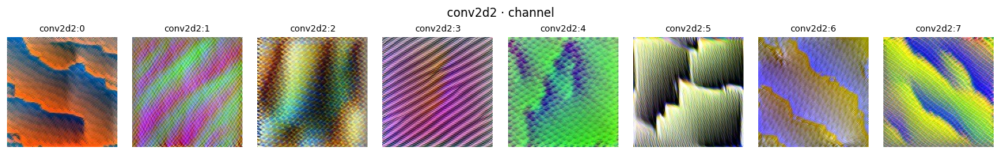

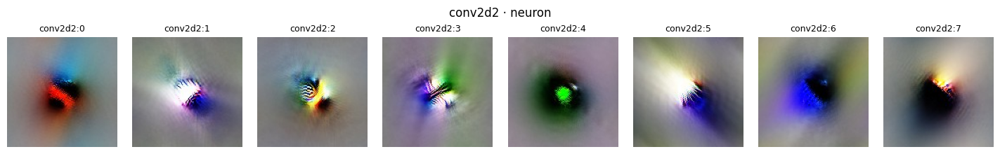

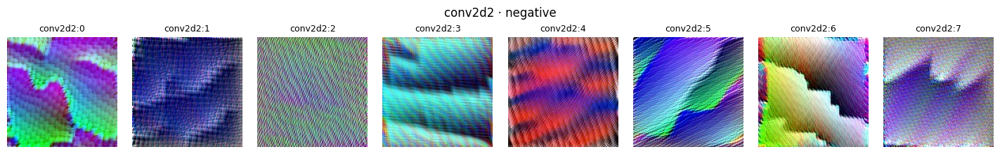

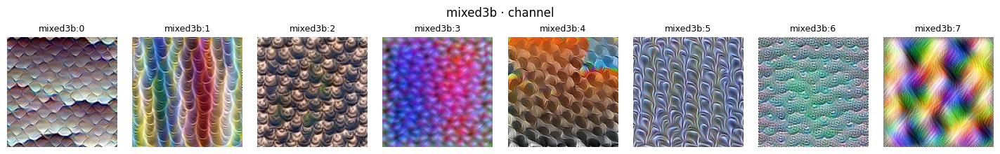

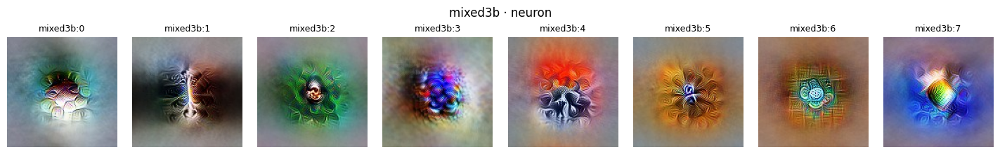

...

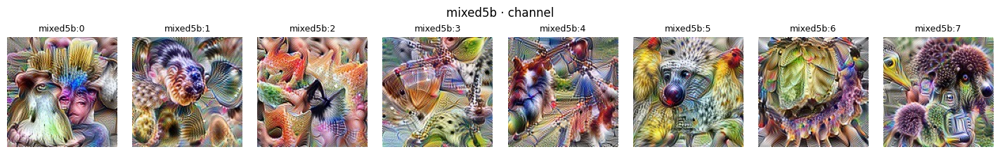

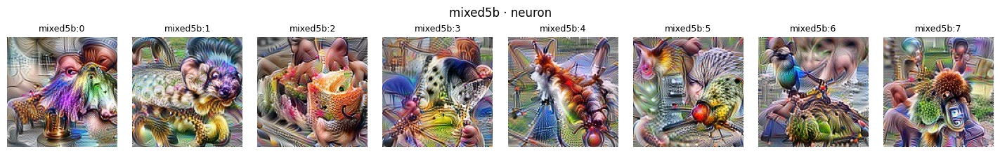

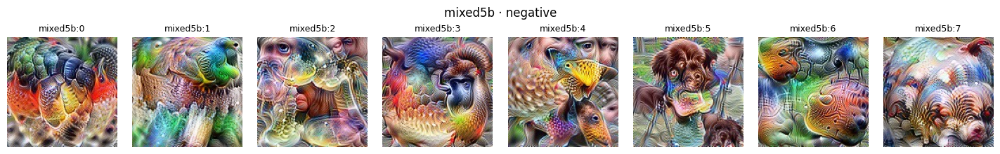

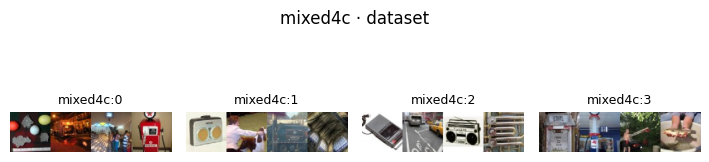

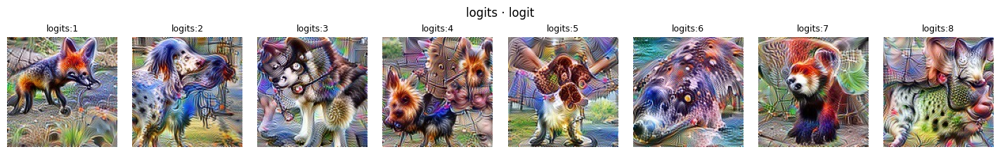

In [14]:
def show_from_atlas(layer, kind, n=8):
    t = next(t for t in TARGETS if t["name"] == layer)
    have = set(existing_indices(t, kind))
    paths = [image_path(t, kind, i) for i in t["indices"][:n] if i in have]
    imgs = [T.functional.to_tensor(Image.open(p)) for p in paths]
    if imgs:
        show(imgs, [f"{layer}:{i}" for i in t["indices"][:len(imgs)]], scale=1.8, suptitle=f"{layer} · {kind}")


for layer in ["conv2d2", "mixed3b", "mixed4c", "mixed5b"]:
    for kind in EXPORT["objectives"]:
        show_from_atlas(layer, kind)
show_from_atlas("mixed4c", "dataset", n=4)
if EXPORT["classes"]:
    show_from_atlas("logits", "logit")

### 10.6 Download

The atlas is already on Google Drive if `USE_DRIVE = True`. To get it locally, zip it and download it (for the
`full` preset this is a few hundred MB, so downloading from Drive directly may be faster). Unzip it next to
`googlenet_architecture.html` so the viewer can find `inceptionv1_atlas/manifest.json`.

In [15]:
import shutil

archive = shutil.make_archive(ATLAS_NAME, "zip", root_dir=os.path.dirname(ATLAS_DIR), base_dir=ATLAS_NAME)
print(f"{archive}: {os.path.getsize(archive) / 1e6:.0f} MB")
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    pass

# Wait until every file written to Drive has actually been uploaded (unmounts Drive; re-run the config cell to remount).
if USE_DRIVE and os.path.ismount("/content/drive"):
    from google.colab import drive
    drive.flush_and_unmount()
    print("all files flushed to Google Drive")

d:\Documentos\Nacho\ATARRAIAredesNeuronales\2026-2\inceptionv1_atlas.zip: 383 MB


## 11. Conclusion and things to try

Feature visualization is one of the basic tools of interpretability, and the article's main lesson is that the
*naive* version of it shows you the network's blind spots rather than its features. Making it work requires
constraining the optimization — through transformation robustness and a decorrelated parameterization — while
being careful not to impose so much of a prior that we stop seeing the network.

Ideas for exploration:

* Sweep a whole layer: render the first 32 channels of `mixed4c` in a grid and look for curves, eyes, fur…
* Compare pre-ReLU and post-ReLU objectives on the same channel.
* Visualize ImageNet classes (`class_logit(CLASSES.index("..."))`) with and without diversity.
* Put the diversity term in a different layer from the objective.
* Implement Lucid's *lowres* shared parameterization for smoother interpolations.
* Swap the model: any `torchvision` CNN works once you hook its layers (`googlenet`, `resnet50`, `vgg16`…).
  Note how much harder some models are to visualize — torchvision's GoogLeNet, for one, comes out covered in a
  checkerboard pattern (see `transform_lab.ipynb`).

**Further reading:** the follow-up Distill articles
[*The Building Blocks of Interpretability*](https://distill.pub/2018/building-blocks/),
[*Differentiable Image Parameterizations*](https://distill.pub/2018/differentiable-parameterizations/) and the
[*Circuits* thread](https://distill.pub/2020/circuits/); the [Lucid](https://github.com/tensorflow/lucid) library
(TensorFlow) and its PyTorch port [Lucent](https://github.com/greentfrapp/lucent), which uses the original
InceptionV1 weights so channel numbers match the articles.